## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Bromberg

**Date:** 10/12/2026

## Q1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

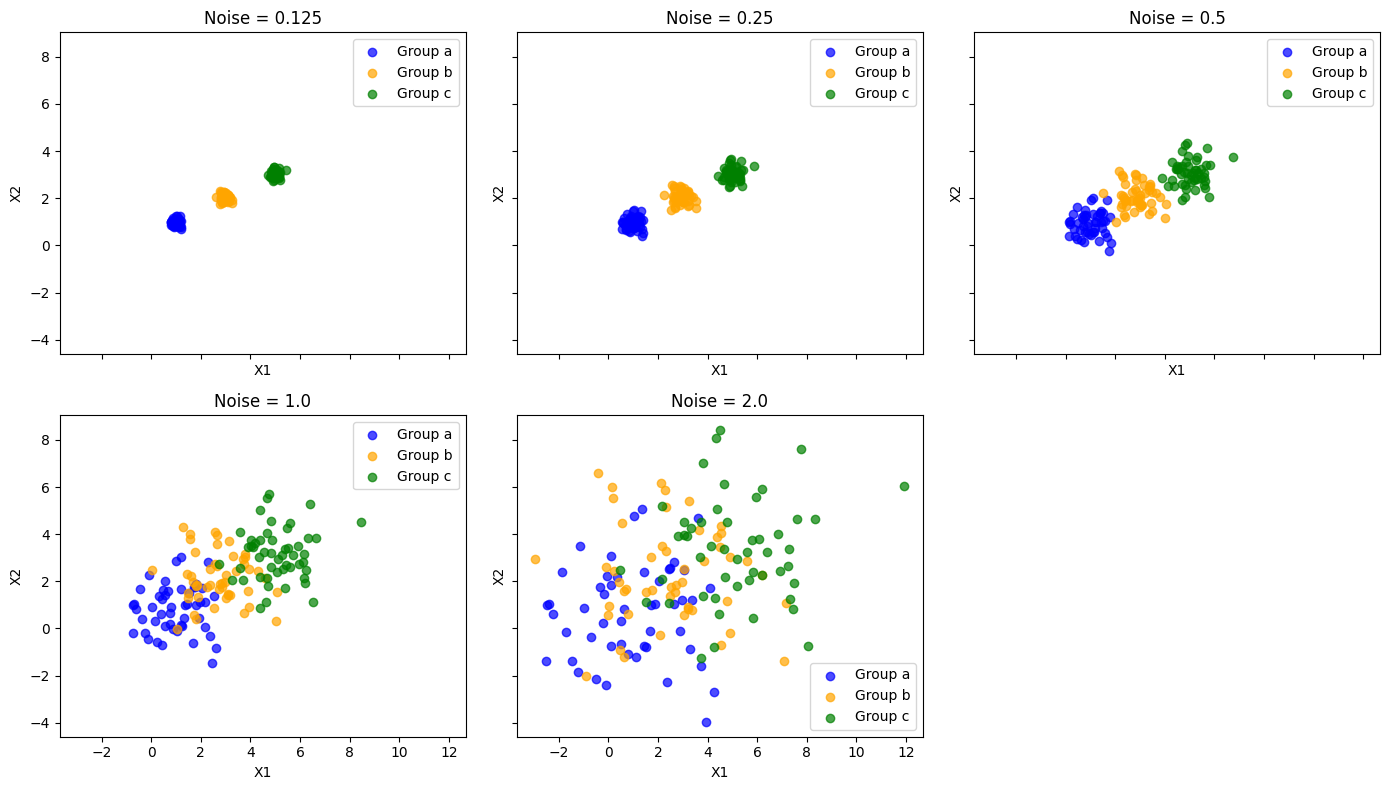

In [3]:
# Making one scatterplot for each noise level
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()

# Use the same color for each group in every plot
colors = {'a': 'blue', 'b': 'orange', 'c': 'green'}

for ax, (noise, df) in zip(axes, datasets.items()):
    # Plot each group separately so it gets its own color
    for group in ['a', 'b', 'c']:
        group_data = df[df['group'] == group]
        ax.scatter(
            group_data['x1'],
            group_data['x2'],
            color=colors[group],
            label=f'Group {group}',
            alpha=0.7
        )

    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.legend()

# Turn off the unused sixth plot
axes[5].axis('off')

plt.tight_layout()
plt.show()

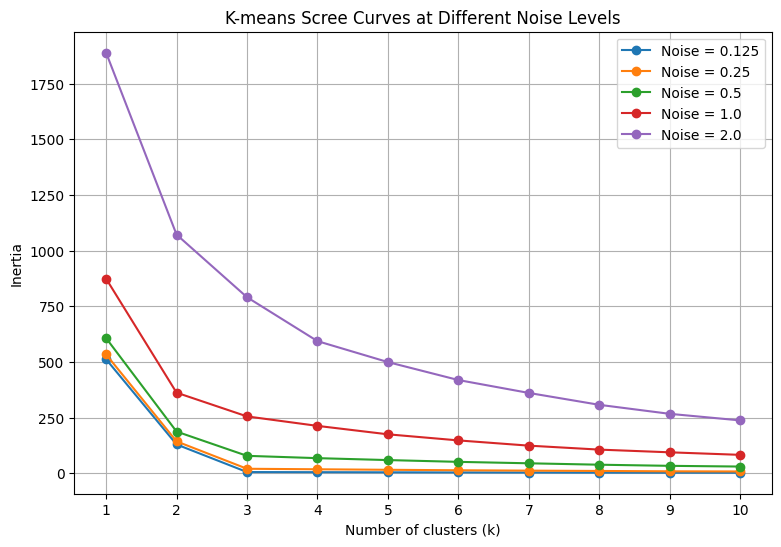

In [4]:
# Try these possible numbers of clusters
k_values = range(1, 11)

# Save the inertia values for each noise level
inertia_results = {}

for noise, df in datasets.items():
    # K-means uses only the two numeric columns
    X = df[['x1', 'x2']]

    inertia_values = []

    for k in k_values:
        # Fit K-means and save its inertia
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    inertia_results[noise] = inertia_values


# Plot all five scree curves on the same axes
plt.figure(figsize=(9, 6))

for noise, inertia_values in inertia_results.items():
    plt.plot(k_values, inertia_values, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('K-means Scree Curves at Different Noise Levels')
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()


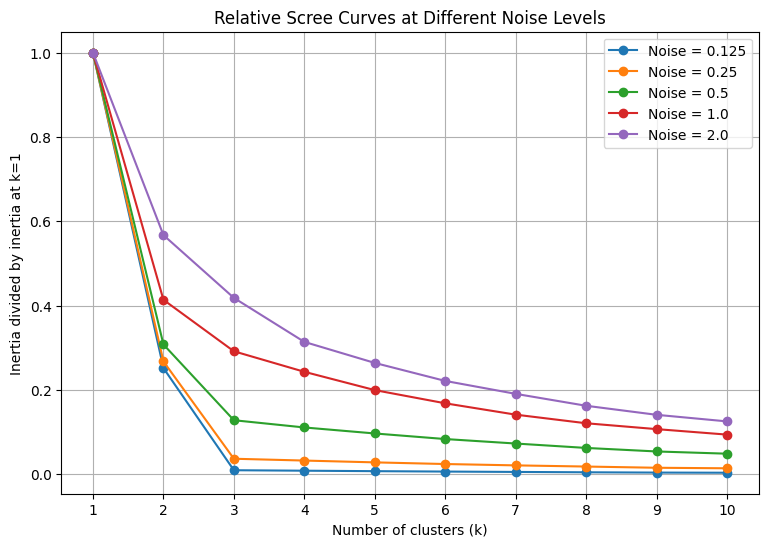

In [5]:
# Plot each curve as a fraction of its inertia when k=1
plt.figure(figsize=(9, 6))

for noise, inertia_values in inertia_results.items():
    relative_inertia = [value / inertia_values[0] for value in inertia_values]
    plt.plot(k_values, relative_inertia, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia divided by inertia at k=1')
plt.title('Relative Scree Curves at Different Noise Levels')
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

### Findings

**Clustering with increasing noise**
* I created five datasets with three groups of 50 points each.
* The groups are centered near (1,1), (3,2), and (5,3), with noise increasing from 0.125 to 2.0 db

**Scatterplots**
* At noise levels 0.125 and 0.25, the three groups are visually distinct.
* At 0.5, the points spread out and begin to overlap.
* At 1.0, the groups are difficult to distinguish.
* At 2.0, the points overlap heavily, so the original groups are no longer visually clear.

**Scree plots**
* At low noise, the scree curve has a clearer elbow around k=3, matching the three groups used to generate the data.
* As noise increases, the elbow becomes less distinct, making the best k harder to choose confidently.

**Elbow Intuition**
* Inertia measures how close points are to their cluster centers. It gets lower as you add clusters.
* The elbow is where adding more clusters stops helping as much. Here, three clusters seem to fit the main groups.
* With more noise, the groups overlap, so it is harder to choose the best number of clusters.

## Q2

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

# Load the CSV file
df = pd.read_csv('/SIPRI Military Expenditure Database.csv')

# Keep only 2020 rows and remove rows with missing values
df2020 = df[df['Year'] == 2020].dropna().copy()

# The index column is just a row number, so I removed it
df2020 = df2020.drop(columns='index')

# Reset the row numbers after filtering
df2020 = df2020.reset_index(drop=True)

print('Number of countries:', len(df2020))
print(df2020.head())

Number of countries: 148
   Year      Country  Spending (2020 USD)  Percent of GDP  \
0  2020  Afghanistan           279.576955        0.013589   
1  2020      Albania           187.433234        0.012583   
2  2020      Algeria          9708.277440        0.066600   
3  2020       Angola           993.594405        0.014442   
4  2020    Argentina          2830.929705        0.007269   

   Percent of Government Spending  Spending per Capita  
0                        0.049728             7.181899  
1                        0.037952            65.126211  
2                        0.173924           221.392384  
3                        0.074624            30.231680  
4                        0.017268            62.636731  


In [7]:
def make_scree_plot(X, title):
    # Calculate inertia for k values from 1 through 10
    k_values = range(1, 11)
    inertia_values = []

    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    # Plot the results
    plt.figure(figsize=(7, 5))
    plt.plot(k_values, inertia_values, marker='o')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Inertia')
    plt.title(title)
    plt.xticks(list(k_values))
    plt.grid(True)
    plt.show()

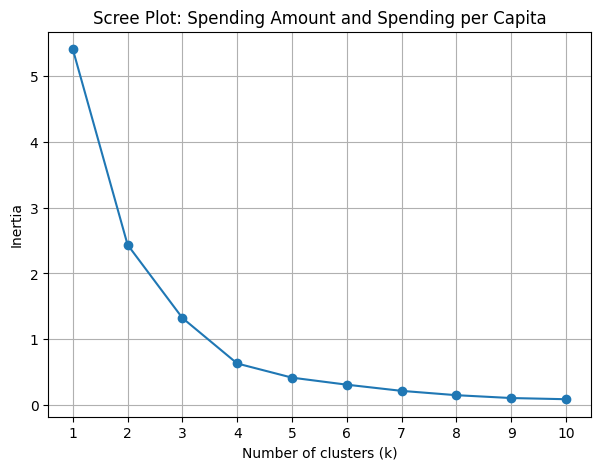

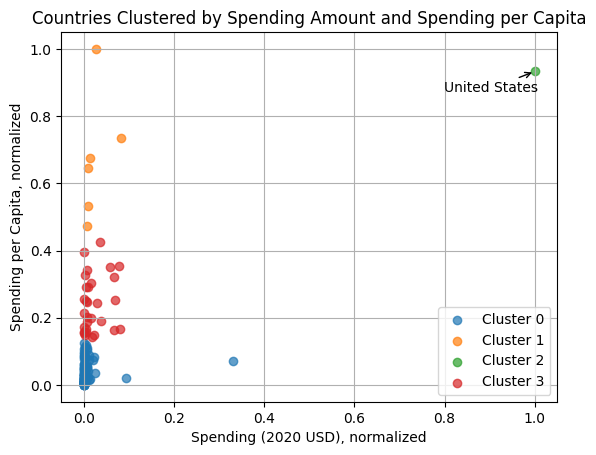

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                       1.0  778397.200000           NaN  778397.200000   
3                      30.0   17077.591354  20583.053357     405.790494   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          2294.039665    5857.060906   26296.001003   61712.537169   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                     111.0    80.061470  ...                       0.083508   
1                       6.0  1706.721916  ...                       0.164503   
2                       1.0  2351.631858  ...                       0.081976   
3                      30.0   607.478618  ...                       0.048819   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.303027          111.0  0.017349  0.011699  0.000054  0.010087   
1        0.225050            6.0  0.059781  0.031979  0.020060  0.035460   
2        0.081976            1.0  0.037179       NaN  0.037179  0.037179   
3        0.114776           30.0  0.019397  0.009272  0.006273  0.013892   

                                       
              50%       75%       max  
cluster                                
0        0.014389  0.021697  0.066600  
1        0.059257  0.085398  0.098470  
2        0.037179  0.037179  0.037179  
3        0.018834  0.022515  0.042634  

[4 rows x 32 columns]

,Country,cluster
144,United States of America,2


In [8]:
spending_cols = ['Spending (2020 USD)', 'Spending per Capita']

# Scale both variables from 0 to 1
scaler = MinMaxScaler()
X_spending = scaler.fit_transform(df2020[spending_cols])

# Make the scree plot
make_scree_plot(X_spending, 'Scree Plot: Spending Amount and Spending per Capita')

# Four clusters is a reasonable choice from the elbow for this pair
spending_model = KMeans(n_clusters=4, random_state=42, n_init=10)
spending_labels = spending_model.fit_predict(X_spending)

# Save the cluster number beside each country's data
spending_results = df2020.copy()
spending_results['cluster'] = spending_labels

# Plot the normalized values, colored by cluster
for cluster in sorted(spending_results['cluster'].unique()):
    points = spending_labels == cluster
    plt.scatter(
        X_spending[points, 0],
        X_spending[points, 1],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

# Marks the United States on the plot
us_row = df2020.index[
    df2020['Country'] == 'United States of America'
][0]

plt.annotate(
    'United States',
    (X_spending[us_row, 0], X_spending[us_row, 1]),
    xytext=(-65, -15),
    textcoords='offset points',
    arrowprops={'arrowstyle': '->'}
)

plt.xlabel('Spending (2020 USD), normalized')
plt.ylabel('Spending per Capita, normalized')
plt.title('Countries Clustered by Spending Amount and Spending per Capita')
plt.legend()
plt.grid(True)
plt.show()

# Compare the original, unscaled values within each cluster
display(spending_results.groupby('cluster')[[
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]].describe())

# Check the United States' cluster
display(spending_results[
    spending_results['Country'] == 'United States of America'
][['Country', 'cluster']])

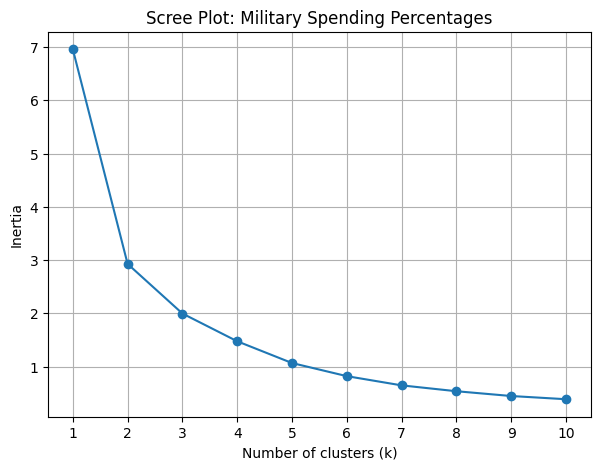

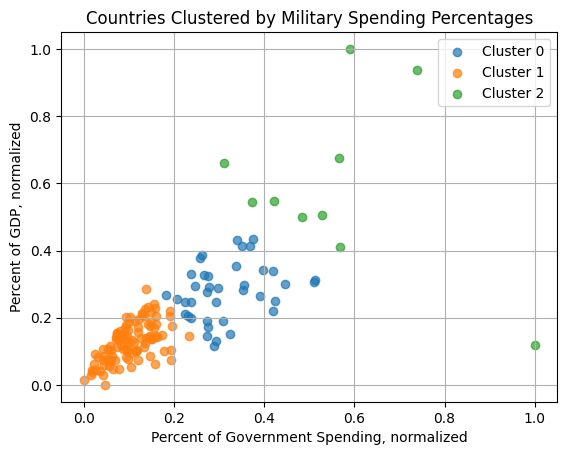

Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                      39.0  27387.150069  124489.244263   44.348098   
1                      99.0   7611.174172   27958.296403    8.622460   
2                      10.0  12514.955945   19365.712246  633.960400   

                                                                \
                 25%          50%           75%            max   
cluster                                                          
0         310.624359  1157.372367   5786.787259  778397.200000   
1         121.641398   567.650747   3910.107493  257973.429834   
2        2101.377796  6518.375529  10222.946276   64558.400000   

        Spending per Capita              ... Percent of Government Spending  \
                      count        mean  ...                            75%   
cluster                                  ...                                  
0                      39.0  271.264618  ...                       0.112633   
1                      99.0  211.624304  ...                       0.047402   
2                      10.0  817.301890  ...                       0.179081   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.157918           39.0  0.027412  0.008191  0.011317  0.021254   
1        0.074624           99.0  0.012664  0.005681  0.000054  0.008393   
2        0.303027           10.0  0.058071  0.024867  0.011742  0.049297   

                                       
              50%       75%       max  
cluster                                
0        0.027781  0.032461  0.042810  
1        0.013191  0.016752  0.028132  
2        0.053729  0.066190  0.098470  

[3 rows x 32 columns]

,Country,cluster
144,United States of America,0


In [9]:
percent_cols = ['Percent of Government Spending', 'Percent of GDP']

# Scale both variables from 0 to 1
scaler = MinMaxScaler()
X_percent = scaler.fit_transform(df2020[percent_cols])

# Make the scree plot
make_scree_plot(X_percent, 'Scree Plot: Military Spending Percentages')

# Three clusters is a reasonable choice for this pair
percent_model = KMeans(n_clusters=3, random_state=42, n_init=10)
percent_labels = percent_model.fit_predict(X_percent)

percent_results = df2020.copy()
percent_results['cluster'] = percent_labels

# Plot the normalized values, colored by cluster
for cluster in sorted(percent_results['cluster'].unique()):
    points = percent_labels == cluster
    plt.scatter(
        X_percent[points, 0],
        X_percent[points, 1],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

plt.xlabel('Percent of Government Spending, normalized')
plt.ylabel('Percent of GDP, normalized')
plt.title('Countries Clustered by Military Spending Percentages')
plt.legend()
plt.grid(True)
plt.show()

# Compare the original values within each cluster
display(percent_results.groupby('cluster')[[
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]].describe())

# Check the United States' cluster
display(percent_results[
    percent_results['Country'] == 'United States of America'
][['Country', 'cluster']])

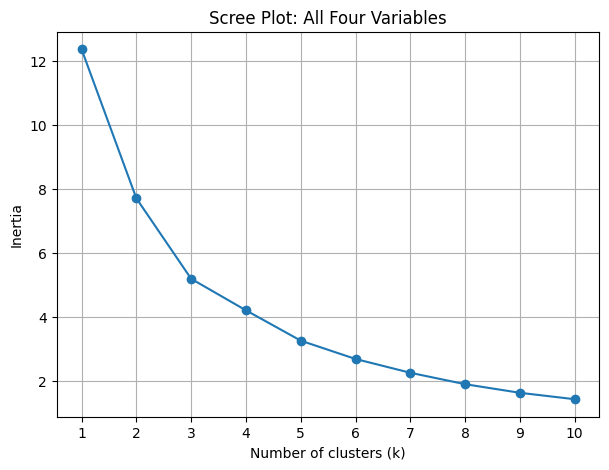

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      31.0    8786.086602   17901.909108   162.373364   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                     111.0    7086.472777   26479.379918     8.622460   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         467.787851   1404.787234   7739.166193   72937.064048   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         130.010211    567.650747   3910.107493  257973.429834   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      31.0   212.689100  ...                       0.134663   
1                       6.0  1875.150751  ...                       0.164503   
2                     111.0   196.926833  ...                       0.050505   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                       
              50%       75%       max  
cluster                                
0        0.032024  0.040531  0.066600  
1        0.059257  0.085398  0.098470  
2        0.013589  0.017769  0.028132  

[3 rows x 32 columns]

,Country,cluster
144,United States of America,1


,Country,cluster
66,Israel,1
75,Kuwait,1
106,Oman,1
117,Saudi Arabia,1
122,Singapore,1
144,United States of America,1


In [10]:
all_cols = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

# Scale all four variables from 0 to 1
scaler = MinMaxScaler()
X_all = scaler.fit_transform(df2020[all_cols])

# Make the scree plot
make_scree_plot(X_all, 'Scree Plot: All Four Variables')

# Three clusters is a reasonable choice from this scree plot
all_model = KMeans(n_clusters=3, random_state=42, n_init=10)
all_labels = all_model.fit_predict(X_all)

all_results = df2020.copy()
all_results['cluster'] = all_labels

# Compare the original values within each cluster
display(all_results.groupby('cluster')[all_cols].describe())

# See which cluster contains the United States
display(all_results[
    all_results['Country'] == 'United States of America'
][['Country', 'cluster']])

# List the countries in the United States' cluster
us_cluster = all_results.loc[
    all_results['Country'] == 'United States of America',
    'cluster'
].iloc[0]

display(all_results[all_results['cluster'] == us_cluster][['Country', 'cluster']])

### Findings:

**Cleaning**
* Filtering to 2020 and dropping rows with missing values leaves 148 countries
* The index column is a row number, so it should be removed. Keep Country to identify cluster members, but exclude it, Year, and index from clustering.
* The four spending variables are already numeric. The percentage columns are stored as proportions: for example, 0.08 means 8%.
* The US has an unusually high spending amount. I kept it because it is meaningful data, but it can affect the clusters.

**Spending Amount & Spending Per Capita**
* I chose k=4 based on the elbow in the scree plot.
* The clusters broadly separate countries with lower spending, higher spending per person, and larger overall budgets.
* The US is by itself in one cluster because its total military spending is much higher than the other countries.

**Percent of government spending and percent of GDP**
* I chose k=3 based on the scree plot.
* The clusters broadly represent lower, middle, and higher military spending as a share of government spending and GDP.
* The US falls in the middle group here

**All four variables**
* I chose k=3 based on the scree plot.
* The US clusters with Israel, Kuwait, Oman, Saudi Arabia, and Singapore
* Most countries fall into a larger cluster with lower percentage shares, but smaller groups have higher values on some or all of the measures.
* The cluster numbers are arbitrary labels, it is better to look at each cluster's profile

**Overall Summary**
* K-means identifies broad similarities between countries, but the results change depending on which variables are included.
* Total spending highlights countries with large military budgets. The percentage variables show military spending relative to a country's economy or government budget.




## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [11]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]